> **Benchmark v2 (21 Nov 2026).** The cells below this note are the original **v1** work, kept for history. Their split is not patient-grouped (or uses the test fold for early stopping or the threshold), so their numbers are optimistic. The official evaluation is the section **v2: patient-grouped 3-fold** at the end of this notebook. Run it from `.venv`.

# **Pre-Process**

# **Deep Learning CNN process**

## v2: patient-grouped 3-fold (Transfer learning, VGG16)

Same protocol for every model (shared code in `audio_engine/evaluation/`):
1. **Folds**: loaded from `Data/processed/splits/v2_patient_grouped/fold_{1,2,3}.csv` (never regenerated here). A PASCAL patient (or PASCAL-A session, or PhysioNet recording) is never in two splits.
2. **Fit** on `train` only. Hyperparameter search (sklearn: inner grouped 3-fold CV inside `train`), early stopping (neural nets) and the **threshold** use `train`/`validation` only.
3. **Test** fold used once, for reporting. Metrics on train, validation and test with the same names for every model.

`RETRAIN = False` reloads the saved results of the last full run; set it to `True` to train again.

In [1]:
import sys
from pathlib import Path
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'audio_engine').is_dir())
sys.path.insert(0, str(root))
from IPython.display import Image, display
from audio_engine.evaluation.folds import load_folds, fold_report, manifest_sha
from audio_engine.evaluation.runners import load_or_run, fold_table
from audio_engine.evaluation.plots import train_vs_test, folds_overview
import pandas as pd

folds = load_folds()   # validates: no group shared between train/validation/test
print('split_manifest_sha =', manifest_sha())
pd.DataFrame(fold_report(folds))

split_manifest_sha = 53829bb5614daaffe5525acd4a1aad7dc622a66859ba90f98f9511428bf46b02


,fold,split,recordings,groups,pascal_patients,normal,abnormal,abnormal_share
0,1,train,2017,1849,85,542,1475,0.731
1,1,validation,507,459,25,136,371,0.732
2,1,test,1261,1147,55,338,923,0.732
3,2,train,2019,1854,89,542,1477,0.732
4,2,validation,504,449,20,135,369,0.732
5,2,test,1262,1152,56,339,923,0.731
6,3,train,2019,1849,91,542,1477,0.732
7,3,validation,504,450,20,135,369,0.732
8,3,test,1262,1156,54,339,923,0.731


In [2]:
RETRAIN = False
result = load_or_run('vgg16_transfer', retrain=RETRAIN)
per_fold, mean_std = fold_table(result)
display(per_fold)
mean_std

,fold,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,specificity
0,1,train,0.413,0.821,0.837,0.945,0.801,0.867,0.795,0.905,0.873
1,1,validation,0.413,0.815,0.841,0.954,0.784,0.861,0.791,0.894,0.897
2,1,test,0.413,0.821,0.825,0.931,0.816,0.870,0.792,0.895,0.834
3,2,train,0.487,0.804,0.842,0.965,0.760,0.850,0.784,0.911,0.924
4,2,validation,0.487,0.812,0.838,0.954,0.780,0.858,0.788,0.894,0.896
5,2,test,0.487,0.777,0.822,0.960,0.726,0.827,0.758,0.894,0.917
6,3,train,0.456,0.826,0.857,0.966,0.789,0.869,0.804,0.923,0.924
7,3,validation,0.456,0.831,0.847,0.949,0.813,0.876,0.806,0.907,0.881
8,3,test,0.456,0.813,0.830,0.942,0.793,0.861,0.787,0.895,0.867


accuracy        balanced_accuracy        precision        recall  \
               mean    std              mean    std      mean    std   mean   
split                                                                         
test          0.804  0.023             0.826  0.004     0.944  0.015  0.778   
train         0.817  0.011             0.845  0.010     0.959  0.012  0.784   
validation    0.819  0.011             0.842  0.005     0.952  0.003  0.793   

                      f1        macro_f1        roc_auc        specificity  \
              std   mean    std     mean    std    mean    std        mean   
split                                                                        
test        0.047  0.852  0.023    0.779  0.018   0.895  0.001       0.873   
train       0.021  0.862  0.010    0.795  0.010   0.913  0.009       0.907   
validation  0.018  0.865  0.009    0.795  0.010   0.898  0.007       0.892   

                   
              std  
split              
test        0.042  
train       0.030  
validation  0.009

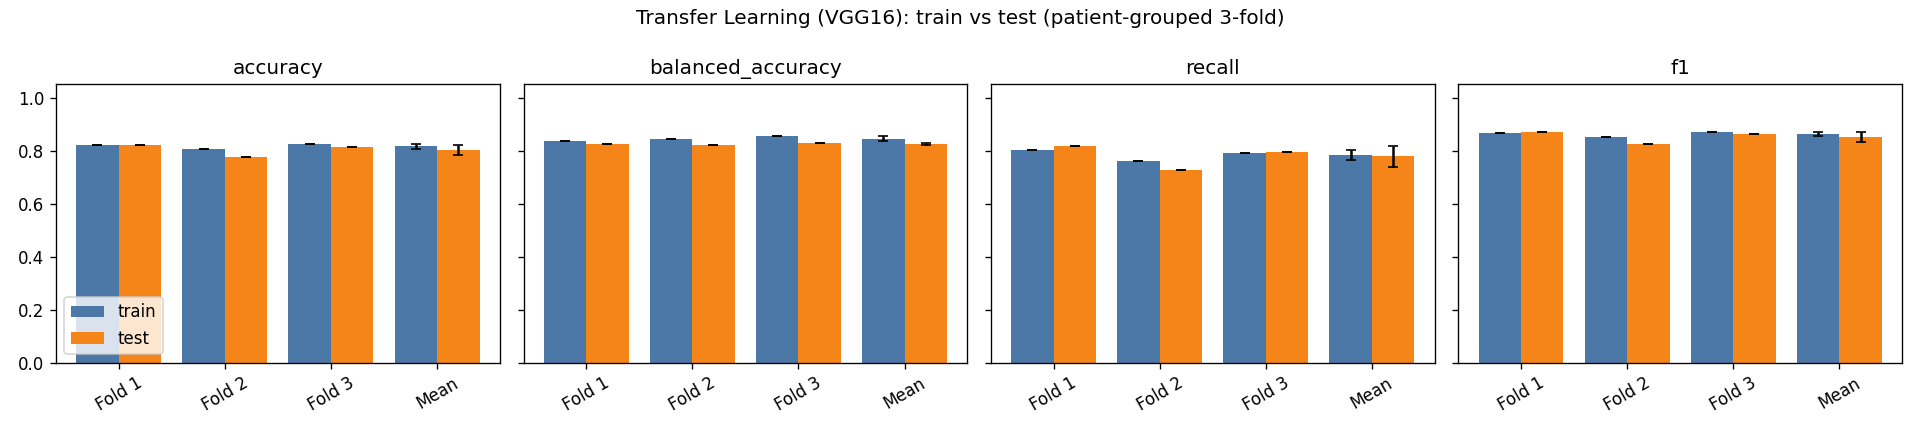

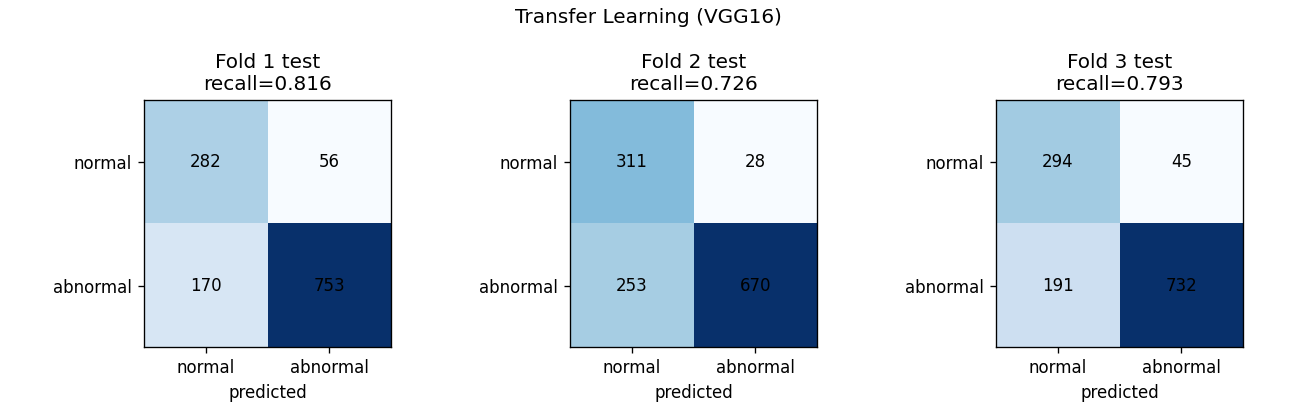

In [3]:
fig_dir = root / 'audio_engine' / 'evaluation' / 'figures' / 'vgg16_transfer'
display(Image(str(train_vs_test(result['folds'], result['display_name'], fig_dir / 'train_vs_test.png'))))
display(Image(str(folds_overview(result['folds'], result['display_name'], fig_dir / 'folds_overview.png'))))